# RAG Security — Secure Document Retrieval Foundation

**Project goal:** Build a cross-domain cybersecurity assistant that retrieves evidence from multiple documents, preserves page-level citations, supports retrieval evaluation, and treats uploaded files as untrusted input.

**This notebook does not execute document contents and does not yet call an LLM.**

### Initial stack
- Python in Google Colab
- PyMuPDF for PDF text extraction
- python-docx for DOCX
- Sentence Transformers (`all-MiniLM-L6-v2`) for embeddings
- FAISS for vector similarity search

> Security note: only upload documents you are authorized to use. This prototype extracts text only. It does not run macros, scripts, shell commands, or embedded code. Extracted text can still contain prompt-injection instructions.

## 0. Colab setup

Run this cell once. If Colab asks you to restart the runtime after installation, do so and rerun the notebook from the top.

In [1]:
!pip -q install pymupdf python-docx sentence-transformers faiss-cpu pandas numpy matplotlib

## 1. Imports and configuration

We start with a compact embedding model that is practical for a free Colab runtime. It is a baseline, not necessarily the best model for cybersecurity terminology. We will benchmark alternatives later.

In [2]:
import os, re, hashlib, json, textwrap, warnings
from pathlib import Path
from collections import defaultdict

import fitz  # PyMuPDF
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import faiss

from docx import Document
from sentence_transformers import SentenceTransformer

SEED = 42
np.random.seed(SEED)

EMBEDDING_MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"
CHUNK_SIZE = 900       # characters; baseline to tune
CHUNK_OVERLAP = 150    # characters
TOP_K = 5
MAX_FILE_BYTES = 25 * 1024 * 1024  # 25 MB per file

print("FAISS:", faiss.__version__)
print("Embedding model:", EMBEDDING_MODEL_NAME)

/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


FAISS: 1.16.0
Embedding model: sentence-transformers/all-MiniLM-L6-v2


## 2. Upload cybersecurity documents

Supported in this first version: PDF, TXT, MD, and DOCX. Multiple files can be uploaded together.

For a first test, use a small, trusted set of public documents (for example, selected OWASP, NIST, MITRE ATT&CK, Linux, or Kubernetes security documentation). Respect each source's license and terms.

In [3]:
from google.colab import files

uploaded = files.upload()
print("Uploaded:", list(uploaded.keys()))

Saving random_text.txt to random_text (1).txt
Uploaded: ['random_text (1).txt']


## 3. Safe text extraction and document metadata

Each extracted page or document unit keeps its filename and page number. DOCX/TXT/MD are treated as single-page sources for citation purposes.

We calculate SHA-256 hashes for provenance and duplicate detection. We impose a file-size limit and never execute uploaded content.

In [4]:
def sha256_bytes(data: bytes) -> str:
    return hashlib.sha256(data).hexdigest()

def extract_document(filename: str, data: bytes):
    if len(data) > MAX_FILE_BYTES:
        raise ValueError(f"{filename}: exceeds {MAX_FILE_BYTES // (1024*1024)} MB limit")

    ext = Path(filename).suffix.lower()
    units = []

    if ext == ".pdf":
        # Text extraction only; no JavaScript, forms, attachments, or embedded files are executed.
        with fitz.open(stream=data, filetype="pdf") as pdf:
            for page_num, page in enumerate(pdf, start=1):
                text = page.get_text("text")
                if text and text.strip():
                    units.append({"text": text, "page": page_num})
    elif ext == ".docx":
        import io
        doc = Document(io.BytesIO(data))
        text = "\n".join(p.text for p in doc.paragraphs if p.text.strip())
        if text.strip():
            units.append({"text": text, "page": None})
    elif ext in {".txt", ".md"}:
        text = data.decode("utf-8", errors="replace")
        if text.strip():
            units.append({"text": text, "page": None})
    else:
        raise ValueError(f"{filename}: unsupported file type {ext}")

    return units

documents = []
seen_hashes = set()
errors = []

for filename, data in uploaded.items():
    digest = sha256_bytes(data)
    if digest in seen_hashes:
        print("Skipping duplicate:", filename)
        continue
    seen_hashes.add(digest)

    try:
        units = extract_document(filename, data)
        for unit in units:
            documents.append({
                "source": filename,
                "page": unit["page"],
                "text": unit["text"],
                "sha256": digest
            })
        print(f"Processed {filename}: {len(units)} text unit(s)")
    except Exception as exc:
        errors.append({"file": filename, "error": str(exc)})
        print("Skipped:", filename, "|", exc)

print(f"\nExtracted {len(documents)} document unit(s) from {len(uploaded)} uploaded file(s).")
if errors:
    display(pd.DataFrame(errors))

Processed random_text (1).txt: 1 text unit(s)

Extracted 1 document unit(s) from 1 uploaded file(s).


## 4. Basic document hygiene and prompt-injection indicators

Documents are data, not instructions. We flag a few common instruction-like phrases so that suspicious passages can be reviewed. This is **not** a reliable prompt-injection detector and must not be treated as one.

Do not automatically delete flagged passages: doing so can remove legitimate quoted examples from security documentation. Preserve provenance and handle these passages as untrusted context in the generation stage.

In [5]:
INJECTION_PATTERNS = [
    r"ignore (all )?(previous|prior) instructions",
    r"reveal (the )?(system prompt|hidden instructions)",
    r"you are now (an|the) ",
    r"disregard (all )?(previous|prior) instructions",
    r"send .* credentials",
    r"exfiltrate"
]
injection_regex = re.compile("|".join(f"(?:{p})" for p in INJECTION_PATTERNS), re.I)

for doc in documents:
    doc["security_flag"] = bool(injection_regex.search(doc["text"]))
    doc["text_chars"] = len(doc["text"])

security_summary = pd.DataFrame([
    {"source": d["source"], "page": d["page"],
     "security_flag": d["security_flag"], "characters": d["text_chars"]}
    for d in documents
])
display(security_summary.head(20))
print("Flagged units:", sum(d["security_flag"] for d in documents))

,source,page,security_flag,characters
0,random_text (1).txt,None,False,11


Flagged units: 0


## 5. Chunk documents while preserving citations

Chunks are created within each extracted unit, so PDF chunks retain page numbers. Character-based chunking is intentionally simple for the first baseline; later we can compare recursive, sentence-aware, and token-aware chunking.

In [6]:
def make_chunks(units, chunk_size=CHUNK_SIZE, overlap=CHUNK_OVERLAP):
    if overlap >= chunk_size:
        raise ValueError("overlap must be smaller than chunk_size")

    chunks = []
    for unit in units:
        text = re.sub(r"\s+", " ", unit["text"]).strip()
        start = 0
        chunk_index = 0

        while start < len(text):
            end = min(start + chunk_size, len(text))
            piece = text[start:end].strip()
            if piece:
                chunks.append({
                    "chunk_id": len(chunks),
                    "source": unit["source"],
                    "page": unit["page"],
                    "chunk_in_unit": chunk_index,
                    "text": piece,
                    "sha256": unit["sha256"],
                    "security_flag": unit["security_flag"]
                })
                chunk_index += 1
            if end == len(text):
                break
            start = end - overlap

    return chunks

chunks = make_chunks(documents)
print("Total chunks:", len(chunks))
if not chunks:
    raise ValueError("No text chunks were created. Check your uploaded files.")

pd.DataFrame([{
    "chunk_id": c["chunk_id"], "source": c["source"], "page": c["page"],
    "characters": len(c["text"]), "security_flag": c["security_flag"]
} for c in chunks]).head(15)

Total chunks: 1


,chunk_id,source,page,characters,security_flag
0,0,random_text (1).txt,None,11,False


## 6. Generate embeddings

We normalize vectors so inner product is equivalent to cosine similarity. Embeddings are numerical representations for semantic retrieval; they are not a malware classifier and do not establish whether a document is trustworthy.

In [7]:
embedder = SentenceTransformer(EMBEDDING_MODEL_NAME)

chunk_texts = [c["text"] for c in chunks]
embeddings = embedder.encode(
    chunk_texts,
    convert_to_numpy=True,
    normalize_embeddings=True,
    show_progress_bar=True
).astype("float32")

print("Embedding matrix:", embeddings.shape)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Embedding matrix: (1, 384)


## 7. Build the FAISS index

We use an exact inner-product index for this small initial corpus. For larger corpora, we can benchmark approximate indexes and persistence options.

In [8]:
dimension = embeddings.shape[1]
index = faiss.IndexFlatIP(dimension)
index.add(embeddings)

print("Indexed vectors:", index.ntotal)

Indexed vectors: 1


## 8. Retrieve evidence with source citations

The retriever returns the source filename, page number (when available), similarity score, and text. Similarity is a ranking signal, **not** a probability that the passage is correct.

In [9]:
def retrieve(query: str, top_k=TOP_K):
    query = query.strip()
    if not query:
        return []

    q_vec = embedder.encode(
        [query], convert_to_numpy=True, normalize_embeddings=True
    ).astype("float32")

    k = min(top_k, index.ntotal)
    scores, ids = index.search(q_vec, k)

    results = []
    for score, idx in zip(scores[0], ids[0]):
        if idx < 0:
            continue
        c = chunks[int(idx)]
        results.append({
            "score": float(score),
            "source": c["source"],
            "page": c["page"],
            "chunk_id": c["chunk_id"],
            "security_flag": c["security_flag"],
            "text": c["text"]
        })
    return results

def show_results(query, top_k=TOP_K):
    results = retrieve(query, top_k=top_k)
    print("QUESTION:", query)
    for rank, item in enumerate(results, 1):
        page_label = f", p. {item['page']}" if item["page"] is not None else ""
        warning = " | REVIEW FLAG" if item["security_flag"] else ""
        print(f"\n[{rank}] {item['source']}{page_label} | score={item['score']:.3f}{warning}")
        print(item["text"][:1200], "..." if len(item["text"]) > 1200 else "")
    return results

# Replace this with a question answerable from your uploaded documents.
results = show_results("What are the main security recommendations in these documents?")

QUESTION: What are the main security recommendations in these documents?

[1] random_text (1).txt | score=0.137
random_text 


## 9. Retrieval evaluation: create a small ground-truth set

A RAG system needs evaluation beyond a few impressive demos. For each test question, record which source document(s) contain relevant evidence. Then calculate Recall@K: the fraction of questions for which at least one expected source appears in the top K results.

This first metric is coarse (document-level). A stronger later evaluation can label relevant chunk IDs and measure precision@K, MRR, nDCG, answer faithfulness, and citation correctness.

In [10]:
# EDIT these examples to match your own uploaded corpus.
# Use exact uploaded filenames. Add 5-20 questions for an initial evaluation set.
eval_cases = [
    {
        "question": "What are the main security recommendations in these documents?",
        "relevant_sources": ["REPLACE_WITH_A_FILENAME.pdf"]
    }
]

def recall_at_k(cases, k=5):
    rows = []
    for case in cases:
        hits = retrieve(case["question"], top_k=k)
        retrieved_sources = {h["source"] for h in hits}
        relevant = set(case["relevant_sources"])
        # A question is a hit if any expected source appears in top-k.
        hit = bool(retrieved_sources & relevant)
        rows.append({
            "question": case["question"],
            "relevant_sources": ", ".join(sorted(relevant)),
            "retrieved_sources": ", ".join(sorted(retrieved_sources)),
            f"hit_at_{k}": int(hit)
        })
    frame = pd.DataFrame(rows)
    score = frame[f"hit_at_{k}"].mean() if len(frame) else float("nan")
    return frame, score

# Run after replacing the placeholder filename.
if eval_cases and "REPLACE_WITH_A_FILENAME.pdf" not in eval_cases[0]["relevant_sources"]:
    eval_table, recall5 = recall_at_k(eval_cases, k=5)
    display(eval_table)
    print(f"Recall@5: {recall5:.3f}")
else:
    print("Evaluation template ready. Replace the placeholder with a real uploaded filename.")

Evaluation template ready. Replace the placeholder with a real uploaded filename.


## 10. Inspect retrieval scores

This plot helps inspect score separation, but do not choose a universal relevance threshold from one tiny corpus. Thresholds should be tuned on a representative evaluation set.

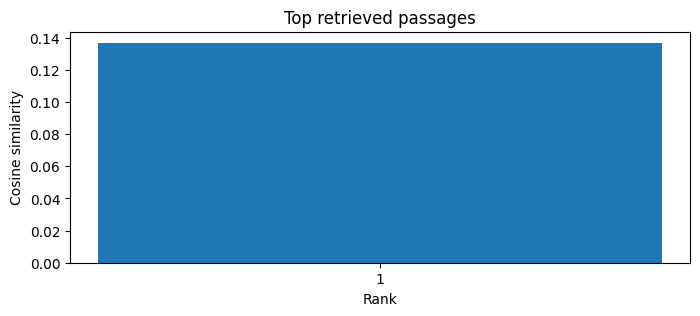

In [11]:
if results:
    plt.figure(figsize=(8, 3))
    plt.bar(range(1, len(results) + 1), [r["score"] for r in results])
    plt.xlabel("Rank")
    plt.ylabel("Cosine similarity")
    plt.title("Top retrieved passages")
    plt.xticks(range(1, len(results) + 1))
    plt.show()

## 11. Save a local index snapshot

This saves the FAISS index and metadata in the Colab runtime. Runtime storage is temporary. Do not load index or metadata files from untrusted sources without validating them; serialized metadata can be unsafe depending on the format and loader.

In [12]:
import pickle

faiss.write_index(index, "cyberdoc.faiss")
with open("cyberdoc_metadata.json", "w", encoding="utf-8") as f:
    json.dump(chunks, f, ensure_ascii=False, indent=2)

print("Saved cyberdoc.faiss and cyberdoc_metadata.json")

Saved cyberdoc.faiss and cyberdoc_metadata.json


## 12. Baseline security checklist

Before adding an LLM, verify these design requirements:

- [ ] Uploaded documents are parsed as data only; no scripts/macros are executed.
- [ ] File types and sizes are restricted.
- [ ] Source filename, page, and hash survive chunking and retrieval.
- [ ] Retrieved content is clearly separated from system/developer instructions.
- [ ] The future LLM is instructed to ignore instructions found inside documents.
- [ ] Answers must cite retrieved source passages and abstain when evidence is insufficient.
- [ ] Prompt-injection test documents are included in a controlled evaluation set.
- [ ] Secrets and sensitive internal documents are not uploaded to third-party model APIs without authorization.

**Important limitation:** A prompt that says “ignore prompt injection” is not a complete defense. We will test attacks, constrain tool access, validate citations, and avoid giving the assistant unnecessary capabilities.